# BÀI TẬP THỰC HÀNH 2
## BÀI 1: KHÁM PHÁ DỮ LIỆU (EDA)
**Dataset sử dụng:** Dataset 1 - Monthly Retail Sales (`a10.csv`)
- Mô tả: Doanh số bán lẻ dược phẩm theo tháng (Australia / US Monthly Sales), từ 07/1991 đến 06/2008..
- Nguồn dữ liệu: https://raw.githubusercontent.com/selva86/datasedf/master/a10.csv

### MỤC TIÊU BÀI 1
1. **Khám phá dữ liệu (EDA) & Trực quan hóa:**
- Tải dữ liệu trực tiếp từ URL.
- Chuyển cột `date` thành chỉ số thời gian (DatetimeIndex).
- Vẽ đồ thị chuỗi thời gian.
- Nhận xét xu hướng, mùa vụ và khả năng dừng của chuỗi.
2. **Trả lời 3 câu hỏi:**
- Chuỗi có xu hướng không?
- Có dấu hiệu mùa vụ không?
- Chuỗi có khả năng dừng không? 

## 1. Import thư viện
Các thư viện dùng để đọc, xử lý và trực quan hóa dữ liệu.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Tải và đọc dữ liệu

In [2]:
url = "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv"
df = pd.read_csv(url)

# Xem vài dòng đầu
print("Kích thước dữ liệu:", df.shape)
print("\nTên cột:", df.columns.tolist())
display(df.head())
display(df.tail())

Kích thước dữ liệu: (204, 2)

Tên cột: ['date', 'value']


,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869


,date,value
199,2008-02-01,21.654285
200,2008-03-01,18.264945
201,2008-04-01,23.107677
202,2008-05-01,22.912510
203,2008-06-01,19.431740


## 3. Chuyển cột date thành chỉ số thời gian
Chuyển `date` sang kiểu ngày tháng, sau đó đặt làm index và sắp xếp theo thời gian.

In [3]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date").sort_index()

display(df.head())
print("Kiểu index:", type(df.index).__name__)
print("Khoảng thời gian:", df.index.min(), "đến", df.index.max())
print("Số quan sát hợp lệ:", len(df))
print("Tần suất thời gian ước tính: hàng tháng")

,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869


Kiểu index: DatetimeIndex
Khoảng thời gian: 1991-07-01 00:00:00 đến 2008-06-01 00:00:00
Số quan sát hợp lệ: 204
Tần suất thời gian ước tính: hàng tháng


## 4. Kiểm tra và mô tả dữ liệu
Thống kê mô tả giúp quan sát mức độ phân tán và phạm vi giá trị.

In [4]:
display(df.describe())

,value
count,204.000000
mean,10.694430
std,5.956998
min,2.814520
25%,5.844095
50%,9.319345
75%,14.289964
max,29.665356


## 5. Vẽ đồ thị chuỗi thời gian

In [5]:
fig, ax = plt.subplodf(figsize=(14, 5))
ax.plot(df.index, df.values, linewidth=1.8, label="Giá trị quan sát")
ax.set_title("Chuỗi thời gian doanh số thuốc theo tháng (A10)", fondfize=14)
ax.set_xlabel("Thời gian")
ax.set_ylabel("Giá trị")
ax.legend()
plt.tight_layout()
plt.show()

AttributeError: module 'matplotlib.pyplot' has no attribute 'subplodf'

## 6. Quan sát xu hướng bằng trung bình trượt

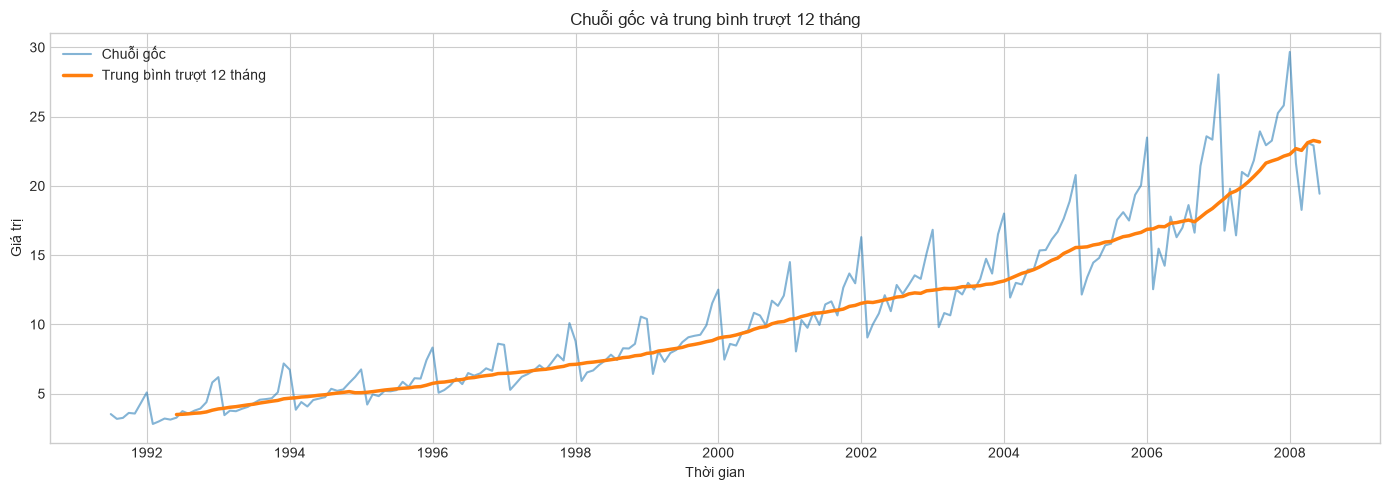

In [ ]:
rolling_12 = df.rolling(window=12, min_periods=12).mean()

fig, ax = plt.subplodf(figsize=(14, 5))
ax.plot(df.index, df.values, alpha=0.55, label="Chuỗi gốc")
ax.plot(rolling_12.index, rolling_12.values, linewidth=2.5, label="Trung bình trượt 12 tháng")
ax.set_title("Chuỗi gốc và trung bình trượt 12 tháng")
ax.set_xlabel("Thời gian")
ax.set_ylabel("Giá trị")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Kiểm tra dấu hiệu mùa vụ

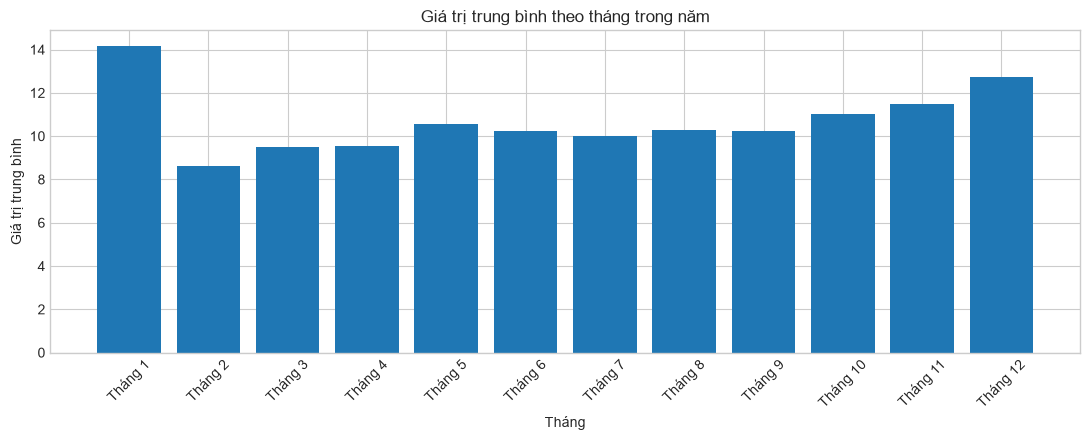

,mean_by_calendar_month
date,
1,14.171518
2,8.612831
3,9.489650
4,9.553137
5,10.563693
6,10.222276
7,9.986016
8,10.264747
9,10.234068


In [ ]:
# Trung bình theo tháng trong năm
month_profile = df.groupby(df.index.month).mean()
month_labels = ["Tháng " + str(m) for m in month_profile.index]

fig, ax = plt.subplodf(figsize=(11, 4.5))
ax.bar(month_labels, month_profile.values)
ax.set_title("Giá trị trung bình theo tháng trong năm")
ax.set_xlabel("Tháng")
ax.set_ylabel("Giá trị trung bình")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

display(month_profile.to_frame("mean_by_calendar_month"))

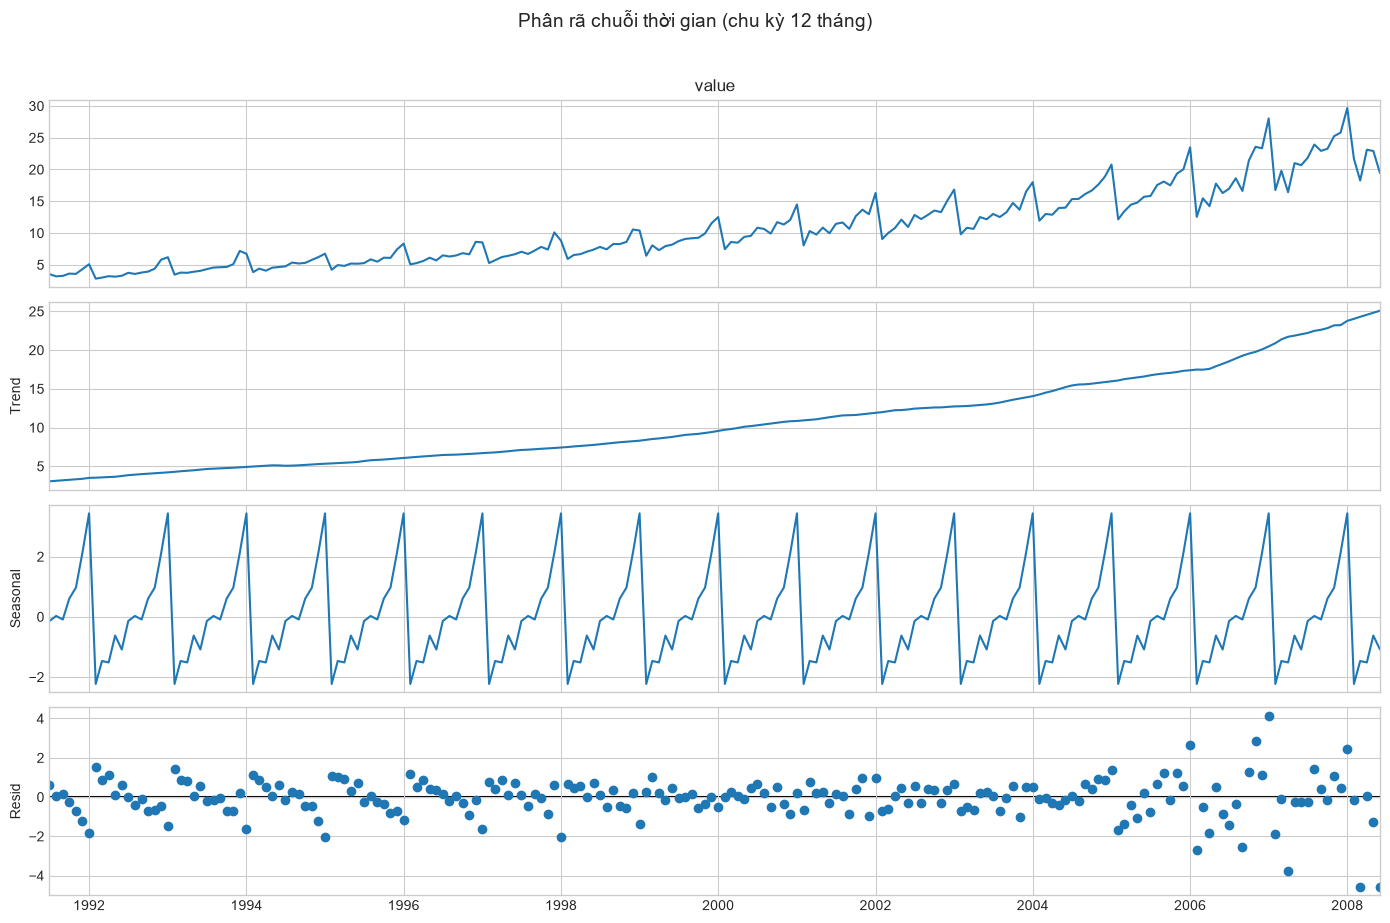

In [ ]:
# Phân rã chuỗi theo chu kỳ 12 tháng để quan sát trend/seasonality/residual
try:
    from stadfmodels.dfa.seasonal import seasonal_decompose

    # Đặt tần suất tháng đầu tháng để phép phân rã nhận diện chu kỳ 12
    df_monthly = df.copy()
    df_monthly.index = df_monthly.index.to_period("M").to_timestamp()
    df_monthly = df_monthly[~df_monthly.index.duplicated(keep="first")].asfreq("MS")
    df_monthly = df_monthly.interpolate(limit_direction="both")

    decomposition = seasonal_decompose(df_monthly, model="additive", period=12, extrapolate_trend="freq")
    fig = decomposition.plot()
    fig.set_size_inches(14, 9)
    fig.suptitle("Phân rã chuỗi thời gian (chu kỳ 12 tháng)", y=1.02, fondfize=14)
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Không thể thực hiện phân rã mùa vụ:", e)
    print("Có thể tiếp tục dựa trên đồ thị chuỗi gốc và trung bình theo tháng.")

## 8. Nhận xét và kết luận

### 1. Chuỗi có xu hướng không?
**Có xu hướng tăng.** Quan sát đồ thị chuỗi thời gian và đường trung bình trượt 12 tháng: giá trị nhìn chung tăng theo thời gian, không dao động quanh một mức cố định.

### 2. Có dấu hiệu mùa vụ không?
**Có dấu hiệu mùa vụ.** Dữ liệu theo tháng có những biến động lặp lại theo các thời điểm trong năm. Biểu đồ trung bình theo tháng và biểu đồ phân rã chu kỳ 12 tháng hỗ trợ quan sát mẫu hình này.

### 3. Chuỗi có khả năng dừng không?
**Chuỗi gốc có khả năng không dừng.** Xu hướng tăng và mẫu hình mùa vụ cho thấy mức trung bình của chuỗi thay đổi theo thời gian, không ổn định quanh một mức cố định.